**Week** **3**: **Data** **Cleaning**

**Objective**:

Handle missing values, remove duplicate records, clean unnecessary columns and prepare the housing dataset for analysis.

### Setup

**Purpose:** Import the libraries so this notebook runs on its own.

_Place `housing_uncleaned.csv` in the same folder (or upload it in Colab) before running._

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Reload the Raw Dataset

**Purpose:** Reload the raw file so the cleaning starts from the original data.

In [29]:
df = pd.read_csv("housing_uncleaned.csv")

**Insight:** Starting from a fresh copy makes the cleaning steps reproducible.

### Total Missing Values

**Purpose:** Count all missing cells in the dataset.

In [30]:
print("Total missing values:",
      df.isnull().sum().sum())

Total missing values: 1219


**Insight:** There are **1,219 missing cells**, which is about 1.4% of the 84,150 cells in the dataset.

### Record the Condition Before Cleaning

**Purpose:** Print rows, columns, missing values and duplicates before cleaning as a baseline.

In [31]:
print("Before Cleaning")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())






Before Cleaning
Rows: 4675
Columns: 18
Missing Values: 1219
Duplicate Rows: 75


**Insight:** Before cleaning: 4,675 rows, 18 columns, 1,219 missing values and 75 duplicate rows.

### Missing Values by Column

**Purpose:** Show column-wise missing counts again for comparison after cleaning.

In [32]:
df.isnull().sum()

,0
date,0
price,90
bedrooms,97
bathrooms,85
sqft_living,107
sqft_lot,92
floors,105
waterfront,84
view,79
condition,84


**Insight:** `sqft_living` (107), `floors` (105) and `yr_built` (99) have the most missing values.

### Remove Duplicates and Handle Missing Values

**Purpose:** Drop duplicate rows, fill numerical missing values with the median and categorical missing values with the mode.

In [33]:
df_clean = df.copy()

# Remove duplicates
df_clean = df_clean.drop_duplicates()

# Fill numerical missing values with median
num_cols = df_clean.select_dtypes(include=np.number).columns

for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

    # Fill categorical missing values with mode
    cat_cols = df_clean.select_dtypes(exclude=np.number).columns

    for col in cat_cols:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])






**Insight:** Median is used because price and area columns are skewed and the mean would be pulled by extreme values. Mode keeps the most common city / street value. Note: `price` is the target, so its 90 imputed rows can also be dropped instead of filled.

### Verify After Cleaning

**Purpose:** Confirm the shape, missing values and duplicates after cleaning.

In [34]:
print("After Cleaning")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())






After Cleaning
Rows: 4600
Columns: 18
Missing Values: 0
Duplicate Rows: 0


**Insight:** After cleaning: **4,600 rows, 18 columns, 0 missing values and 0 duplicates**. Only the 75 duplicate rows (1.6%) were removed, so almost all of the data is retained.

### Update Feature Lists

**Purpose:** Recreate the numerical and categorical column lists for outlier analysis.

In [35]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", num_cols)

print("\nCategorical columns:", cat_cols)

Numerical columns: ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated']

Categorical columns: ['date', 'street', 'city', 'statezip', 'country']


**Insight:** The split stays the same (13 numerical, 5 categorical). These lists are used by the boxplots and the IQR outlier check below.

### Upload the Cleaned File

**Purpose:** Upload the saved `housing_cleaned.csv` back into the session.

In [36]:
from google.colab import files

uploaded = files.upload()

Saving housing_cleaned.csv to housing_cleaned (1).csv


**Insight:** This keeps the cleaned data available for Week 4 even after the Colab runtime restarts.

### Save the Cleaned Dataset

**Purpose:** Save `df_clean` as `housing_cleaned.csv` (with a fallback that reruns the cleaning if the DataFrame is missing).

In [37]:
# Save the cleaned dataset
try:
    df_clean.to_csv("housing_cleaned.csv", index=False)
    print("Cleaned dataset saved successfully!")
except NameError:
    print("df_clean was not defined in memory. Re-running cleaning process first...")
    import pandas as pd
    import numpy as np
    import os

    # Check if the raw file exists
    if not os.path.exists("housing_uncleaned.csv"):
        print("Error: 'housing_uncleaned.csv' not found. Please upload it to your Colab files panel before running this cell.")
    else:
        df = pd.read_csv("housing_uncleaned.csv")
        df_clean = df.copy()
        df_clean = df_clean.drop_duplicates()

        # Fill numerical missing values with median
        num_cols = df_clean.select_dtypes(include=np.number).columns
        for col in num_cols:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())

        # Fill categorical missing values with mode
        cat_cols = df_clean.select_dtypes(exclude=np.number).columns
        for col in cat_cols:
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

        df_clean.to_csv("housing_cleaned.csv", index=False)
        print("Cleaned dataset saved successfully after recreating df_clean!")

Cleaned dataset saved successfully!


**Insight:** The cleaned dataset is stored as a CSV and becomes the input for the EDA in Week 4.

### Download the Cleaned Dataset

**Purpose:** Download the cleaned file to the local computer.

In [38]:
from google.colab import files

files.download("housing_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Insight:** A local backup of the cleaned data is available for the team and the presentation.

### Outlier Detection Using Boxplots

**Purpose:** Draw a boxplot for each numerical column to see extreme values visually.

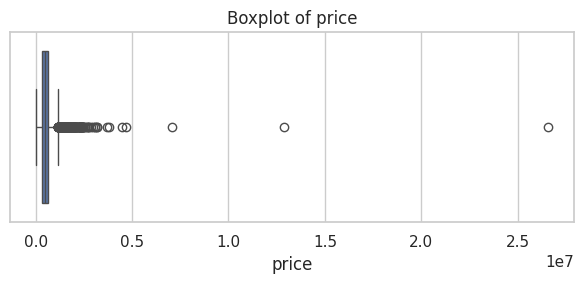

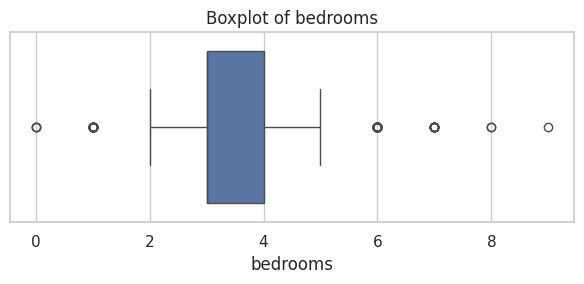

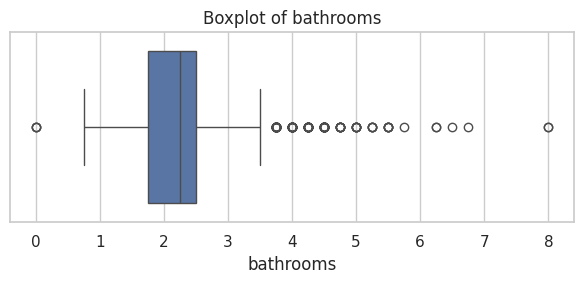

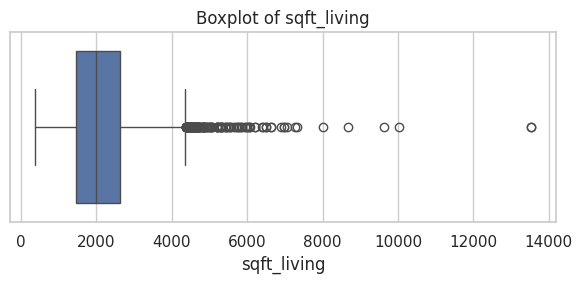

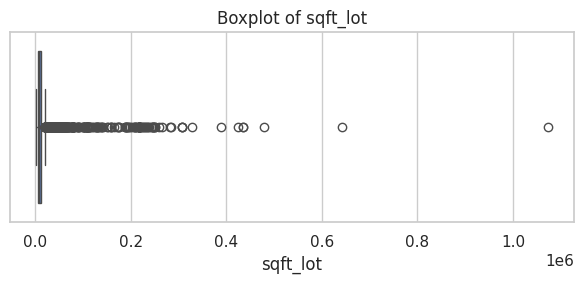

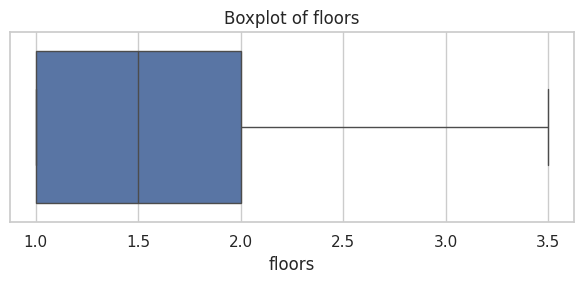

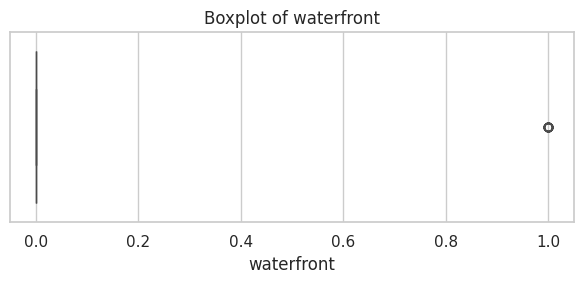

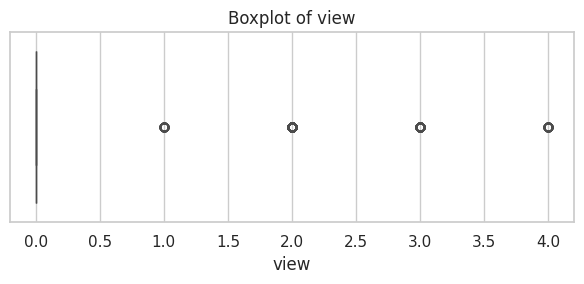

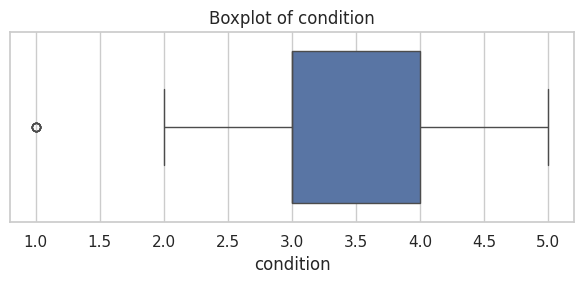

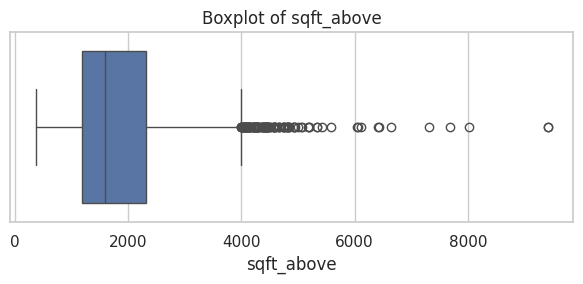

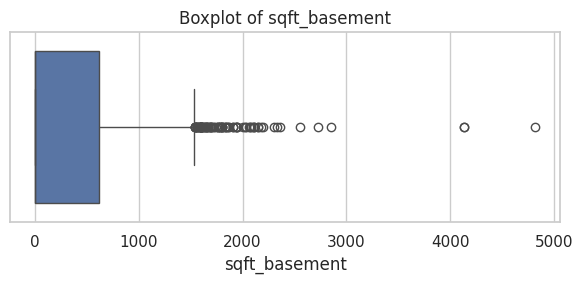

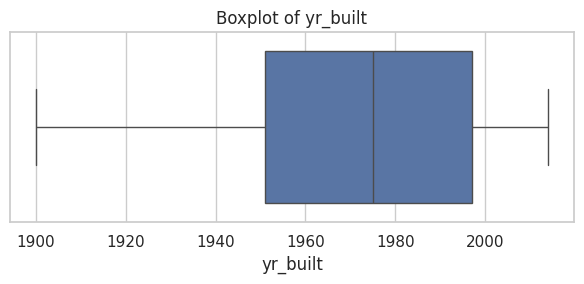

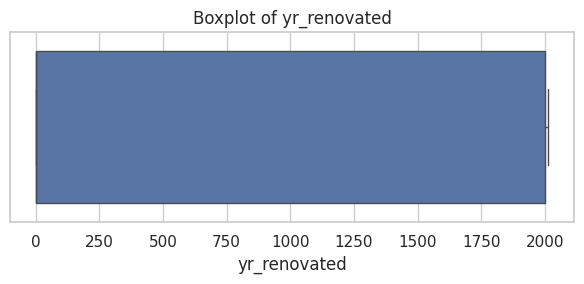

In [39]:
for col in num_cols:
      plt.figure(figsize=(6, 3))
      sns.boxplot(x=df[col])
      plt.title(f"Boxplot of {col}")
      plt.tight_layout()
      plt.show()

**Insight:** Several columns (especially price, sqft_lot and sqft_living) have many points outside the whiskers, so the data has extreme values on the high side. The exact counts are given by the IQR method below.

### Outlier Detection Using IQR

**Purpose:** Count values outside Q1 - 1.5 x IQR and Q3 + 1.5 x IQR for each numerical column.

In [40]:
outlier_report = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outlier_report[col] = len(outliers)

    print(col, "-> outliers:", len(outliers))

price -> outliers: 244
bedrooms -> outliers: 121
bathrooms -> outliers: 150
sqft_living -> outliers: 136
sqft_lot -> outliers: 544
floors -> outliers: 0
waterfront -> outliers: 34
view -> outliers: 464
condition -> outliers: 6
sqft_above -> outliers: 117
sqft_basement -> outliers: 84
yr_built -> outliers: 0
yr_renovated -> outliers: 0


**Insight:** `sqft_lot` has the most outliers (**544**), then `view` (464), `price` (244), `bathrooms` (150), `sqft_living` (136) and `bedrooms` (121). `floors`, `yr_built` and `yr_renovated` have none. `view`, `waterfront` and `condition` are small-scale category-like numbers, so their IQR outliers are not real extreme values. These outliers are only identified here, not removed.

### Week 3 Conclusion

Duplicate records were removed and all missing values were filled with the median (numerical) and mode (categorical). The cleaned dataset has 4,600 rows, 18 columns, 0 missing values and 0 duplicates and was saved as `housing_cleaned.csv`.

Boxplots and the IQR method identified outliers, mainly in `sqft_lot`, `view` and `price`. They were identified but not removed.

The next stage will focus on Exploratory Data Analysis (EDA).